# Análisis Exploratorio y Resultados - Laboratorio 02
**Asignatura:** Machine Learning (2026-02)  
**Integrantes:** Martín Droguett y Amelie Valderrama  
**Objetivo:** Comparación de embeddings faciales lineales (PCA, LDA y Fisherfaces) sobre Olivetti y LFW.

In [6]:
import pandas as pd
from src.datos.olivetti import CargadorOlivetti
from src.datos.lfw import CargadorLFW

# Cargar datasets
olivetti = CargadorOlivetti().cargar()
lfw = CargadorLFW().cargar()

print("=== CARACTERÍSTICAS DE LOS CONJUNTOS ===")
print(f"Olivetti -> Muestras (N): {olivetti.X.shape[0]}, Clases (C): {olivetti.n_clases}, Resolución: {olivetti.alto}x{olivetti.ancho} (píxeles: {olivetti.X.shape[1]})")
print(f"LFW      -> Muestras (N): {lfw.X.shape[0]}, Clases (C): {lfw.n_clases}, Resolución: {lfw.alto}x{lfw.ancho} (píxeles: {lfw.X.shape[1]})")

=== CARACTERÍSTICAS DE LOS CONJUNTOS ===
Olivetti -> Muestras (N): 400, Clases (C): 40, Resolución: 64x64 (píxeles: 4096)
LFW      -> Muestras (N): 2773, Clases (C): 50, Resolución: 62x47 (píxeles: 2914)


In [8]:
# Cargar resultados de los experimentos
df_res = pd.read_csv("data/resultados/resultados_modelos.csv")

print("\n--- RESUMEN EXPERIMENTAL: OLIVETTI ---")
tabla_olivetti = df_res[df_res["dataset"] == "olivetti"].pivot_table(
    index=["embedding", "d"], columns="modelo", values=["accuracy", "macro_f1"]
)
display(tabla_olivetti)

print("\n--- RESUMEN EXPERIMENTAL: LFW ---")
tabla_lfw = df_res[df_res["dataset"] == "lfw"].pivot_table(
    index=["embedding", "d"], columns="modelo", values=["accuracy", "macro_f1"]
)
display(tabla_lfw)


--- RESUMEN EXPERIMENTAL: OLIVETTI ---


accuracy              macro_f1                    
modelo            arbol   knn   svm     arbol       knn       svm
embedding   d                                                    
fisherfaces 10     0.44  0.80  0.90  0.398790  0.779524  0.896190
            20     0.37  0.95  0.98  0.293364  0.937024  0.978095
            30     0.29  0.95  0.96  0.250032  0.941429  0.959524
lda         10     0.30  0.99  0.98  0.302679  0.990000  0.980000
            20     0.28  0.97  0.97  0.262921  0.968095  0.969524
            30     0.31  0.97  0.96  0.297776  0.969524  0.957619
pca         10     0.31  0.78  0.86  0.266705  0.772679  0.851548
            20     0.36  0.83  0.95  0.340456  0.825734  0.946548
            30     0.33  0.84  0.98  0.302976  0.831190  0.979524


--- RESUMEN EXPERIMENTAL: LFW ---


accuracy                      macro_f1                    
modelo             arbol       knn       svm     arbol       knn       svm
embedding   d                                                             
fisherfaces 10  0.244957  0.216138  0.332853  0.120056  0.124279  0.176450
            20  0.311239  0.344380  0.438040  0.172499  0.258347  0.320795
            30  0.293948  0.402017  0.484150  0.152440  0.308251  0.395485
lda         10  0.119597  0.182997  0.175793  0.053752  0.095169  0.103805
            20  0.105187  0.246398  0.219020  0.039259  0.159347  0.157062
            30  0.112392  0.269452  0.243516  0.043343  0.169298  0.176892
pca         10  0.221902  0.191643  0.329971  0.065241  0.125886  0.172970
            20  0.208934  0.233429  0.440922  0.082750  0.149763  0.321716
            30  0.216138  0.272334  0.485591  0.088935  0.192730  0.383481

1. Curvas de Varianza Acumulada PCA (Olivetti y LFW):


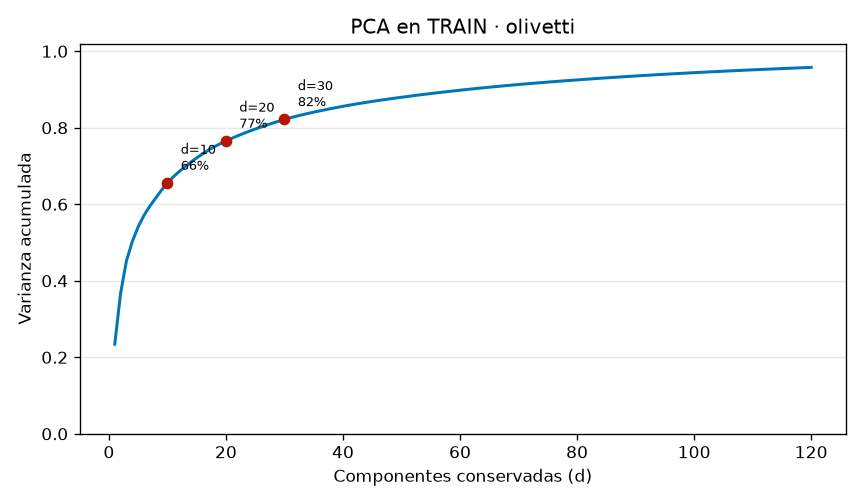

2. Mapa t-SNE Fisherfaces d=20 (Olivetti):


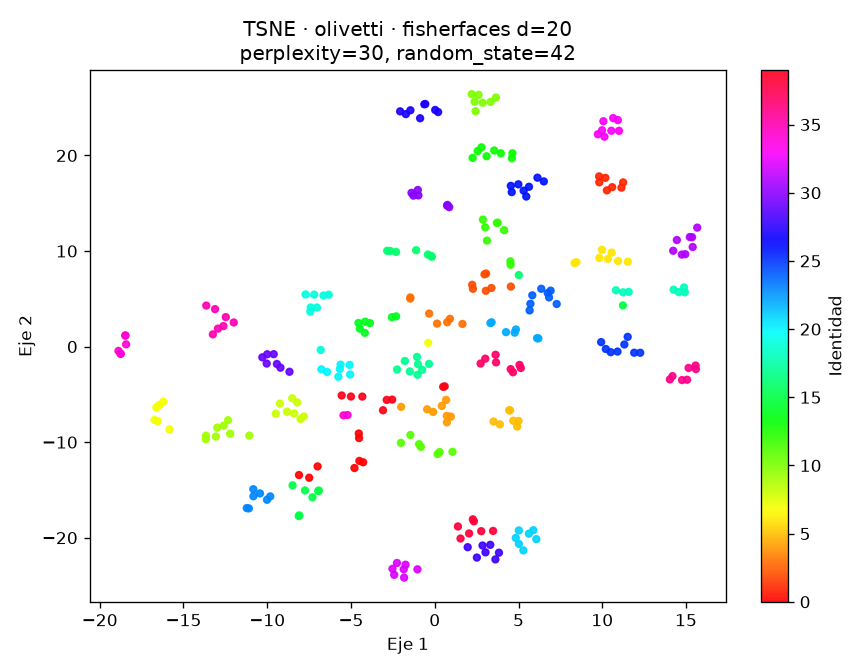

In [10]:
from IPython.display import Image, display

print("1. Curvas de Varianza Acumulada PCA (Olivetti y LFW):")
display(Image(filename="figuras/curva_pca_olivetti.png", width=600))

print("2. Mapa t-SNE Fisherfaces d=20 (Olivetti):")
display(Image(filename="figuras/tsne_olivetti_fisherfaces_d20.png", width=600))